# CAPTAIN zero-shot assessment: MS dataset (GSE144744)

Compares CAPTAIN's predicted protein levels with the measured ones for one sample.
Both pickles **must come from the same CAPTAIN run** (the same results folder), and the `.h5ad` files must be the ones that run used.

In [2]:
%matplotlib inline
import pickle
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

## 1. Paths (edit these)

In [3]:
RESULTS_DIR = './secondCaptainValidation'                       # CAPTAIN output folder for this sample
RNA_H5AD    = './secondCaptainValidation/captain_input/HH-OX-02_rna.h5ad'   # the files given to CAPTAIN
ADT_H5AD    = './secondCaptainValidation/captain_input/HH-OX-02_adt.h5ad'
MEASURED    = './secondCaptainValidation/captain_input/HH-OX-02_measured_proteins.csv'
TOKEN_DICT  = 'csp_token_dict.pickle'
CELLTYPE_COL = 'basictype'      # or 'cluster_names' for finer types

## 2. Load predictions and measurements
The pickles hold one entry per batch; stacking turns them into a (cells x proteins) table.

In [4]:
with open(f'{RESULTS_DIR}/true_adt_data_scale.pickle', 'rb') as f:
    trueData = pickle.load(f)
with open(f'{RESULTS_DIR}/predicted_adt_scale.pickle', 'rb') as f:
    predictedData = pickle.load(f)
with open(TOKEN_DICT, 'rb') as f:
    tokenDict = pickle.load(f)

n_prot = len(tokenDict)
true = np.concatenate([np.asarray(b, dtype=float).reshape(-1, n_prot) for b in trueData])
predicted = np.concatenate([np.asarray(b, dtype=float).reshape(-1, n_prot) for b in predictedData])
print('true:', true.shape, '  predicted:', predicted.shape)

if true.shape != predicted.shape:
    raise ValueError('The two pickles have different numbers of cells, so they come from different runs. '
                     'Copy both files from the same results folder.')

proteinNames = np.array([name.strip() for name in sorted(tokenDict, key=tokenDict.get)])   # column order

true: (6704, 387)   predicted: (6704, 387)


## 3. Keep only proteins measured in this sample
Columns for proteins this panel didn't measure are all zeros. A protein is kept if it is in the panel, varies across cells, and isn't `TCR.V` (a catch-all token mixing several different TCR antibodies).

In [5]:
in_panel = set(pd.read_csv(MEASURED, header=None)[0].astype(str).str.strip())
varies = true.std(axis=0) > 0
keep = np.array([(name in in_panel) and v and name != 'TCR.V' for name, v in zip(proteinNames, varies)])

dropped = sorted(n for n in in_panel if n not in set(proteinNames[keep]))
print(f'{keep.sum()} proteins kept; left out: {dropped}')

true2, predicted2, names2 = true[:, keep], predicted[:, keep], proteinNames[keep]

36 proteins kept; left out: ['TCR.V']


## 4. Accuracy per protein, across all cells

In [13]:
rows = []
for i, name in enumerate(names2):
    t, p = true2[:, i], predicted2[:, i]
    rows.append({'protein': name,
                 'pearson_r': pearsonr(t, p)[0],
                 'spearman_rho': spearmanr(t, p)[0],
                 'rmse': np.sqrt(np.mean((p - t) ** 2))})

results = pd.DataFrame(rows).sort_values('pearson_r', ascending=False)
print(results.to_string(index=False))
print(f"\nMedian Pearson r across {len(results)} proteins: {results['pearson_r'].median():.3f}")

protein  pearson_r  spearman_rho     rmse
   CD14   0.903158      0.542966 0.459522
    CD4   0.886173      0.797730 0.764214
    CD8   0.848790      0.444916 0.556617
 CD45RA   0.799902      0.778535 0.629713
   CD27   0.799540      0.788840 0.727979
    CD3   0.797575      0.728889 0.797427
  HLADR   0.736464      0.541434 0.814328
   CD29   0.718080      0.729365 0.705401
 CD45RO   0.700987      0.687342 0.730153
   CD38   0.603018      0.639966 0.818569
   CD28   0.587604      0.597958 0.917766
   CD95   0.488081      0.474999 0.912252
  CD123   0.422418      0.138660 0.935594
  CD161   0.379437      0.281668 0.951240
   CD57   0.339883      0.143874 0.940553
   CD19   0.339361      0.093070 0.964495
    IgD   0.327818      0.139497 0.976195
  CD127   0.319955      0.343600 1.496589
   CD16   0.294281      0.186402 0.970227
   CD56   0.293700      0.120370 0.979533
  CD196   0.265278      0.206920 0.970875
   CD24   0.222235      0.087535 0.978256
   CD25   0.187407      0.174749 1

## 5. Attach cell types
CAPTAIN keeps cells in their original order but drops cells with fewer than 200 RNA counts, so the same filter is applied here before lining cells up.

In [14]:
rna = ad.read_h5ad(RNA_H5AD)
adt_raw = ad.read_h5ad(ADT_H5AD)

counts = np.asarray(rna.X.sum(axis=1)).ravel()
obs = rna.obs[counts >= 200]
print(f'{len(obs)} cells after the >=200 counts filter; CAPTAIN output has {true.shape[0]}')

if len(obs) != true.shape[0]:
    raise ValueError('Cell counts differ: these .h5ad files are not the ones this CAPTAIN run used.')
celltype = obs[CELLTYPE_COL].astype(str).values
print(pd.Series(celltype).value_counts().to_string())

6704 cells after the >=200 counts filter; CAPTAIN output has 6704
t_cells         4616
monocytes       1496
nk_cells         364
pdc               85
b_cells           67
cdc               66
plasma_cells       7
platelets          3


## 6. Accuracy within each cell type
Correlations across all cells can look good just because the model separates cell types (e.g. B vs T cells).
Within-type correlations test whether it also captures variation inside a population. Cell types with fewer than 100 cells are skipped.

In [15]:
MIN_CELLS = 100
per_type = {}
for ct in pd.Series(celltype).value_counts().index:
    idx = celltype == ct
    if idx.sum() < MIN_CELLS:
        continue
    per_type[ct] = {}
    for i, name in enumerate(names2):
        t, p = true2[idx, i], predicted2[idx, i]
        per_type[ct][name] = pearsonr(t, p)[0] if t.std() > 0 and p.std() > 0 else np.nan

per_type = pd.DataFrame(per_type).loc[results['protein']]
per_type.insert(0, 'all_cells', results.set_index('protein')['pearson_r'])
print(per_type.round(2).to_string())

        all_cells  t_cells  monocytes  nk_cells
CD14         0.90     0.10       0.60      0.01
CD4          0.89     0.89       0.42      0.14
CD8          0.85     0.87       0.63      0.39
CD45RA       0.80     0.74       0.41      0.30
CD27         0.80     0.61       0.37      0.29
CD3          0.80     0.38       0.40      0.16
HLADR        0.74     0.19       0.54      0.07
CD29         0.72     0.59       0.32      0.39
CD45RO       0.70     0.72       0.46      0.19
CD38         0.60     0.51       0.45      0.55
CD28         0.59     0.46       0.15      0.20
CD95         0.49     0.46       0.27      0.04
CD123        0.42     0.09       0.14      0.02
CD161        0.38     0.42       0.16      0.14
CD57         0.34     0.33       0.09      0.44
CD19         0.34     0.08       0.10     -0.00
IgD          0.33     0.14       0.14     -0.04
CD127        0.32     0.25       0.06      0.17
CD16         0.29     0.11       0.26      0.46
CD56         0.29     0.11       0.04   

## 7. Scatter plots
Values are on CAPTAIN's scaled units (mean 0, SD 1 per protein); the dashed line is perfect agreement.

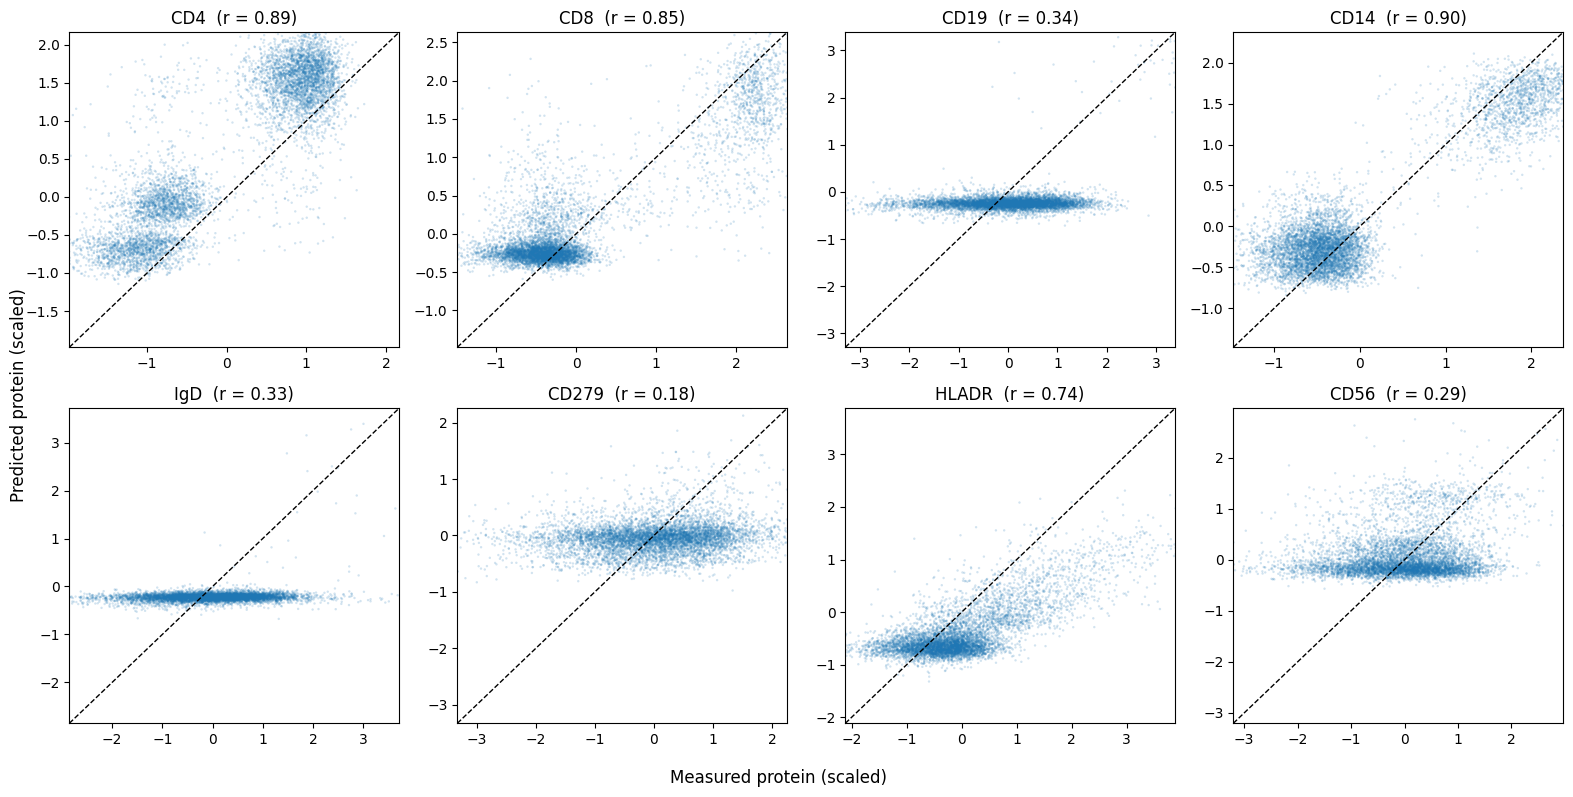

In [16]:
PLOT = ['CD4', 'CD8', 'CD19', 'CD14', 'IgD', 'CD279', 'HLADR', 'CD56']
PLOT = [p for p in PLOT if p in set(names2)]

ncol = 4
nrow = int(np.ceil(len(PLOT) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 4 * nrow), squeeze=False)
for ax, name in zip(axes.flat, PLOT):
    i = list(names2).index(name)
    t, p = true2[:, i], predicted2[:, i]
    ax.scatter(t, p, s=3, alpha=0.2, color='tab:blue', edgecolor='none')
    lo = min(np.percentile(t, 0.5), np.percentile(p, 0.5))
    hi = max(np.percentile(t, 99.5), np.percentile(p, 99.5))
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f'{name}  (r = {pearsonr(t, p)[0]:.2f})')
for ax in list(axes.flat)[len(PLOT):]:
    ax.axis('off')
fig.supxlabel('Measured protein (scaled)')
fig.supylabel('Predicted protein (scaled)')
plt.tight_layout()
plt.show()

## 8. Raw antibody counts (data quality check)
Antibodies detected in very few cells were probably not stained well in this sample; treat their correlations with caution.

median ADT counts per cell: 775.0
        mean_counts  fraction_detected
CD45RA    67.535004              1.000
CD25      66.651001              1.000
CD14      56.284000              1.000
CD4       55.466000              1.000
CD27      44.091999              1.000
CD8       43.074001              0.999
HLADR     41.917999              1.000
CD29      32.317001              1.000
IgD       31.511000              1.000
CD38      29.993999              1.000
CD3       24.646000              1.000
CD95      23.514000              1.000
CD138     22.785000              1.000
CD185     22.705000              1.000
CD197     21.561001              1.000
CD45RO    21.291000              0.999
CD28      20.191999              1.000
CD24      19.479000              1.000
CD279     18.259001              1.000
CD57      18.039000              1.000
CD16      18.000000              1.000
CD196     17.968000              1.000
CD11c     15.855000              0.999
CD49d     15.518000           

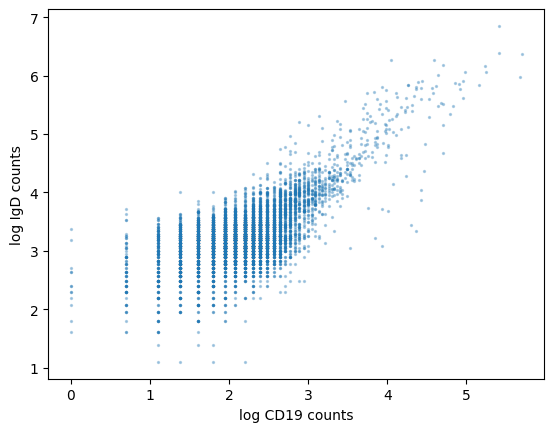

In [17]:
X = adt_raw.X
tot = np.asarray(X.sum(axis=1)).ravel()
print('median ADT counts per cell:', np.median(tot))

summary = pd.DataFrame({
    'mean_counts': np.asarray(X.mean(axis=0)).ravel(),
    'fraction_detected': np.asarray((X > 0).mean(axis=0)).ravel(),
}, index=adt_raw.var_names).sort_values('mean_counts', ascending=False)
print(summary.round(3).to_string())

# B-cell markers should go together: IgD+ cells should also be CD19+
if {'IgD', 'CD19'} <= set(adt_raw.var_names):
    igd = np.asarray(adt_raw[:, 'IgD'].X.todense()).ravel()
    cd19 = np.asarray(adt_raw[:, 'CD19'].X.todense()).ravel()
    plt.scatter(np.log1p(cd19), np.log1p(igd), s=2, alpha=0.3)
    plt.xlabel('log CD19 counts'); plt.ylabel('log IgD counts'); plt.show()

In [18]:
EXPECTED_ON = {
    'CD14': 'classical monocytes', 'CD4': 'CD4 T cells (low on monocytes)', 'CD8': 'CD8 T cells (some NK cells)',
    'CD45RA': 'naive T cells, B cells, NK cells', 'CD45RO': 'memory T cells', 'CD27': 'naive/memory T cells, memory B cells',
    'CD3': 'T cells', 'HLADR': 'B cells, monocytes, DCs, activated T cells', 'CD29': 'most leukocytes (high on memory T cells)',
    'CD38': 'plasmablasts, NK cells, monocytes, activated T cells', 'CD28': 'most T cells (lost on terminally differentiated)',
    'CD95': 'memory and activated T cells', 'CD123': 'plasmacytoid DCs, basophils', 'CD161': 'MAIT cells, NK cells, Th17 cells',
    'CD57': 'terminally differentiated NK and CD8 T cells', 'CD19': 'B cells', 'IgD': 'naive B cells',
    'CD127': 'most T cells (low on Tregs)', 'CD16': 'CD56-dim NK cells, non-classical monocytes', 'CD56': 'NK cells',
    'CD196': 'Th17 cells, memory T cells, B cells', 'CD24': 'B cells', 'CD25': 'regulatory and activated T cells',
    'CD279': 'activated/exhausted T cells, Tfh cells', 'CD197': 'naive and central memory T cells, B cells',
    'CD11c': 'myeloid DCs, monocytes', 'CD138': 'plasma cells', 'TCR.gd': 'gamma-delta T cells',
    'CD314': 'NK cells, CD8 T cells', 'CCR10': 'skin-homing T cells, some plasma cells',
    'CD49': 'most lymphocytes and monocytes (CD49d; catch-all token)', 'CD159a': 'NK cells (CD56-bright), some CD8 T cells',
    'CD194': 'Th2 cells, Tregs, skin-homing memory T cells', 'CD152': 'Tregs, activated T cells (mostly inside the cell)',
    'CD183': 'Th1 cells, memory CD8 T cells, NK cells', 'CD185': 'B cells, Tfh cells', 'TCR.V': 'MAIT cells (catch-all token)',
}
ALIASES = {'CD49': 'CD49d'}     # CAPTAIN token -> antibody name in the ADT file, where they differ
MIN_TYPE_CELLS = 20

adt_cells = adt_raw[obs.index]                  # same cells, same order as the predictions
raw_names = {v.strip(): v for v in adt_cells.var_names}
types = pd.Series(celltype).value_counts()
types = types[types >= MIN_TYPE_CELLS].index

rows = []
for name in names2:
    col = raw_names.get(name) or raw_names.get(ALIASES.get(name, ''))
    row = {'protein': name}
    if col is None:
        print(f'{name}: no matching column in the ADT file')
    else:
        x = adt_cells[:, col].X
        counts = np.asarray(x.todense() if hasattr(x, 'todense') else x).ravel()
        by_type = {t: counts[celltype == t].mean() for t in types}
        top = max(by_type, key=by_type.get)
        row.update({'mean_counts': counts.mean(), 'median_counts': np.median(counts),
                    'highest_in': top, 'mean_in_highest': by_type[top]})
    row['expected_on'] = EXPECTED_ON.get(name, '')
    rows.append(row)

summary = (results.set_index('protein')[['pearson_r']]
           .join(pd.DataFrame(rows).set_index('protein'))
           .sort_values('pearson_r', ascending=False))
pd.set_option('display.max_colwidth', 60)
display(summary.round(2))
summary.round(3).to_csv(f'{RESULTS_DIR}/protein_summary.csv')

,pearson_r,mean_counts,median_counts,highest_in,mean_in_highest,expected_on
protein,,,,,,
CD14,0.90,56.279999,19.0,monocytes,187.960007,classical monocytes
CD4,0.89,55.470001,52.0,t_cells,64.650002,CD4 T cells (low on monocytes)
CD8,0.85,43.070000,15.0,t_cells,49.910000,CD8 T cells (some NK cells)
CD45RA,0.80,67.540001,39.5,b_cells,286.489990,"naive T cells, B cells, NK cells"
CD27,0.80,44.090000,43.0,t_cells,49.349998,"naive/memory T cells, memory B cells"
CD3,0.80,24.650000,23.0,t_cells,28.650000,T cells
HLADR,0.74,41.919998,28.0,b_cells,233.570007,"B cells, monocytes, DCs, activated T cells"
CD29,0.72,32.320000,23.0,monocytes,64.500000,most leukocytes (high on memory T cells)
CD45RO,0.70,21.290001,15.0,monocytes,28.690001,memory T cells


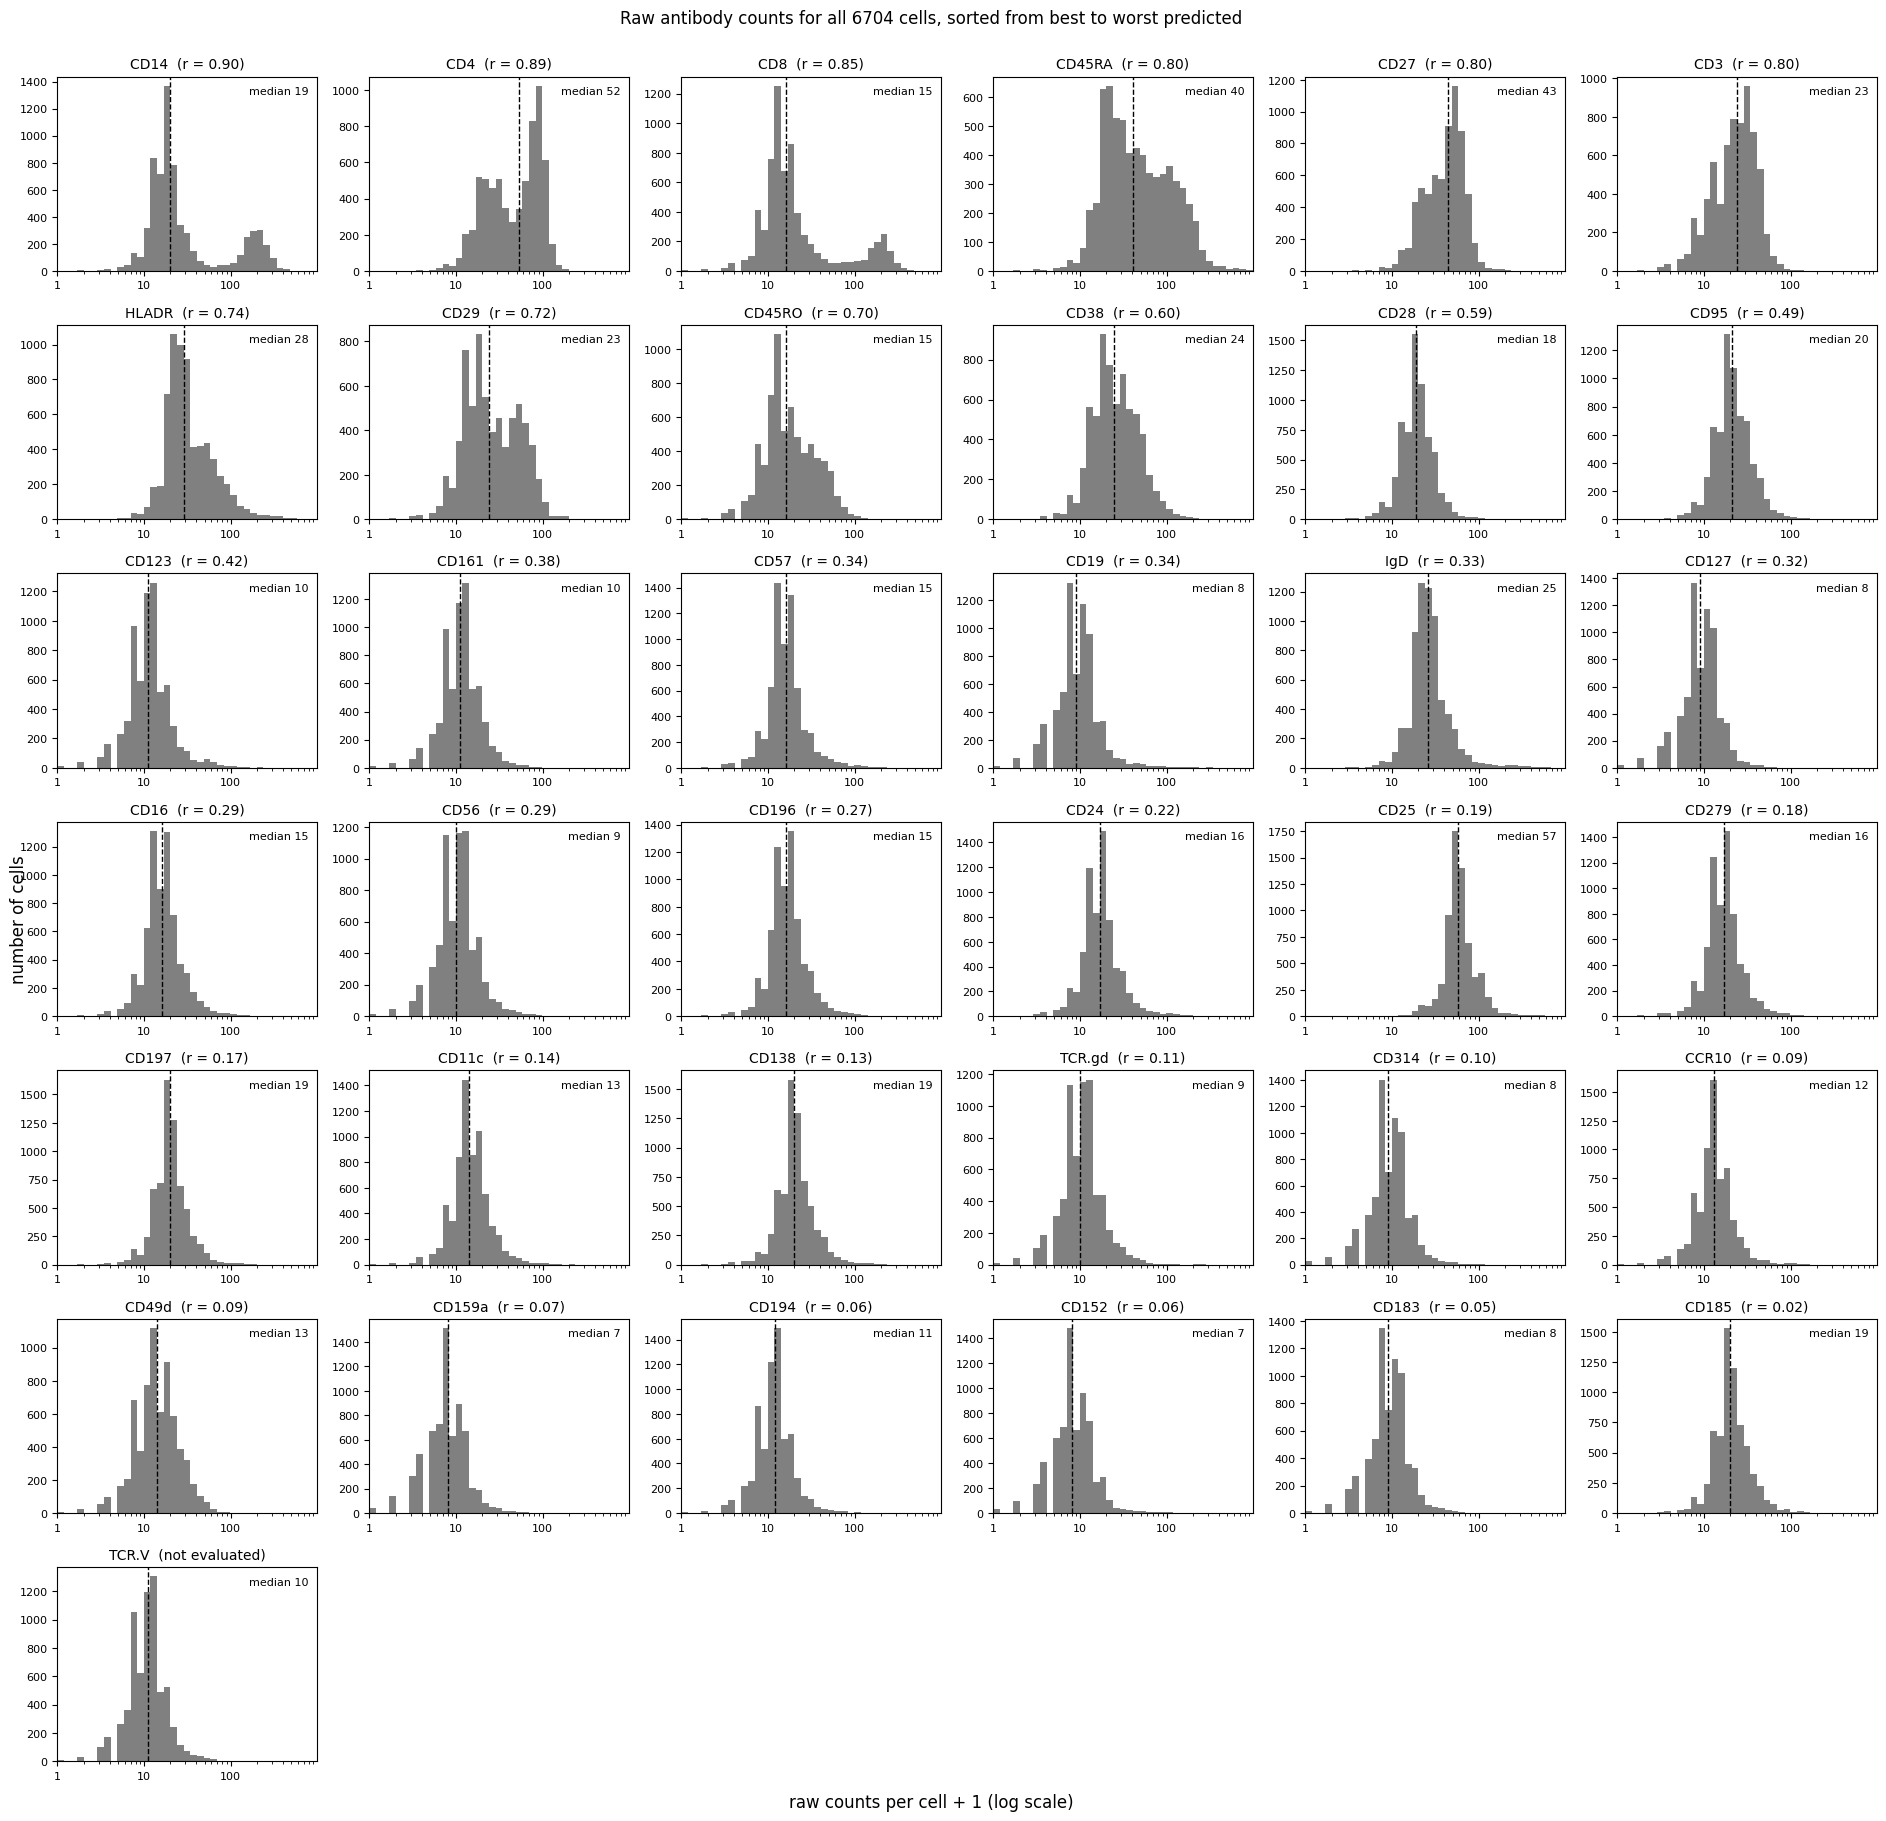

In [19]:
import matplotlib.ticker as mticker

NCOLS = 6        # panels per row
LOG_X = True     # True: log scale with ticks at 1, 10, 100, 1000 (evenly spaced); False: ordinary linear scale
LOG_Y = False    # set True to make small populations visible
SAME_X = True    # same x-range in every panel, so ticks line up and proteins can be compared directly

r_of = results.set_index('protein')['pearson_r']
TOKEN_OF = {'CD49d': 'CD49'}                         # antibody name in the ADT file -> CAPTAIN token, where they differ
names = [v.strip() for v in adt_raw.var_names]
tokens = [TOKEN_OF.get(n, n) for n in names]
order = sorted(range(len(names)), key=lambda i: -r_of.get(tokens[i], -np.inf))   # best first, unevaluated last

X = adt_raw.X
X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)    # all cells in the ADT file, no filtering

x_max = X.max()
nrows = int(np.ceil(len(order) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(3.2 * NCOLS, 2.6 * nrows), squeeze=False)
for ax, i in zip(axes.flat, order):
    counts = X[:, i]
    med = np.median(counts)
    top = x_max if SAME_X else counts.max()
    if LOG_X:
        values = counts + 1                                        # +1 so cells with 0 counts can be shown on a log axis
        bins = np.logspace(0, np.log10(max(top + 1, 10)), 40)
        ax.hist(values, bins=bins, color='grey')
        ax.set_xscale('log')
        ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
        ax.xaxis.set_minor_formatter(mticker.NullFormatter())
        ax.axvline(med + 1, color='k', ls='--', lw=1)
        ax.set_xlim(1, bins[-1])
    else:
        bins = np.arange(-0.5, top + 1.5) if top < 60 else np.linspace(0, top, 40)   # one bar per count when the range is small
        ax.hist(counts, bins=bins, color='grey')
        ax.set_xlim(bins[0], bins[-1])
        ax.xaxis.set_major_locator(mticker.MaxNLocator(5, integer=True))
        ax.axvline(med, color='k', ls='--', lw=1)
    ax.tick_params(labelsize=8)
    r = r_of.get(tokens[i])
    ax.set_title(f'{names[i]}  (r = {r:.2f})' if r is not None else f'{names[i]}  (not evaluated)', fontsize=10)
    ax.text(0.97, 0.95, f'median {med:.0f}', transform=ax.transAxes, ha='right', va='top', fontsize=8)
    if LOG_Y:
        ax.set_yscale('log')
for ax in list(axes.flat)[len(order):]:
    ax.axis('off')
fig.supxlabel('raw counts per cell + 1 (log scale)' if LOG_X else 'raw counts per cell')
fig.supylabel('number of cells')
fig.suptitle(f'Raw antibody counts for all {X.shape[0]} cells, sorted from best to worst predicted', y=1.0)
plt.tight_layout()
plt.show()

Not found in Supplementary Data 15: []
Not evaluated (excluded in section 3): ['TCR.V']

protein  training_frequency  pearson_r
   CD19               0.792      0.339
  CD11c               0.776      0.143
   CD38               0.773      0.603
    CD3               0.765      0.798
 CD45RA               0.761      0.800
  CD279               0.733      0.179
  CD127               0.725      0.320
   CD25               0.722      0.187
   CD56               0.714      0.294
   CD16               0.694      0.294
 CD45RO               0.690      0.701
   CD28               0.682      0.588
  CD123               0.624      0.422
    CD4               0.604      0.886
   CD24               0.604      0.222
    CD8               0.596      0.849
  CD197               0.592      0.171
  CD183               0.576      0.049
   CD14               0.573      0.903
  CD161               0.569      0.379
   CD57               0.565      0.340
   CD49               0.561      0.089
   CD29       

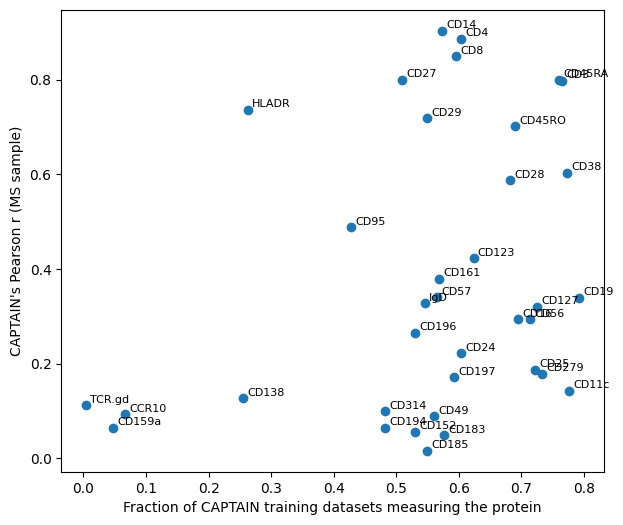

In [20]:
from scipy.stats import spearmanr

SUPP_FILE = './secondCaptainValidation/CAPTAIN_supplementary_data.xlsx'

# 1. Training frequency of every protein (Supplementary Data 15)
sd15 = pd.read_excel(SUPP_FILE, sheet_name='Supplementary Data 15')
sd15 = sd15.rename(columns={sd15.columns[0]: 'sd15_name', sd15.columns[1]: 'frequency'})
sd15['key'] = sd15['sd15_name'].astype(str).str.strip().str.upper()
freq_of = sd15.drop_duplicates('key').set_index('key')['frequency']

# 2. Every protein in the MS panel that went into CAPTAIN, with its training frequency and r in this sample
ms = pd.DataFrame({'protein': sorted(in_panel)})
ms['training_frequency'] = ms['protein'].str.strip().str.upper().map(freq_of)
#ms['n_training_datasets'] = (ms['training_frequency'] * 255).round()
ms = ms.merge(results[['protein', 'pearson_r']], on='protein', how='left')
ms = ms.sort_values('training_frequency', ascending=False)

print('Not found in Supplementary Data 15:', ms.loc[ms['training_frequency'].isna(), 'protein'].tolist())
print('Not evaluated (excluded in section 3):', ms.loc[ms['pearson_r'].isna(), 'protein'].tolist())
print('\n' + ms.round(3).to_string(index=False))
ms.to_csv(f'{RESULTS_DIR}/ms_protein_training_frequency.csv', index=False)

# 3. Does training frequency go with accuracy in this sample?
both = ms.dropna(subset=['training_frequency', 'pearson_r'])
rho, p = spearmanr(both['training_frequency'], both['pearson_r'])
print(f'\nSpearman rho between training frequency and Pearson r: {rho:.2f} (p = {p:.3g}, n = {len(both)})')

plt.figure(figsize=(7, 6))
plt.scatter(both['training_frequency'], both['pearson_r'])
for _, row in both.iterrows():
    plt.annotate(row['protein'], (row['training_frequency'], row['pearson_r']), fontsize=8,
                 xytext=(3, 2), textcoords='offset points')
plt.xlabel('Fraction of CAPTAIN training datasets measuring the protein')
plt.ylabel("CAPTAIN's Pearson r (MS sample)")
plt.show()

In [21]:
adt_cells = adt_raw[obs.index]                      # same cells, same order as the predictions
raw_names = {v.strip(): v for v in adt_cells.var_names}
ALIASES = {'CD49': 'CD49d'}                         # CAPTAIN token -> antibody name in the ADT file

def fraction_detected(protein, min_counts=1):
    """Fraction of cells in this MS sample with at least `min_counts` raw counts for the protein."""
    col = raw_names.get(protein) or raw_names.get(ALIASES.get(protein, ''))
    if col is None:
        return np.nan
    x = adt_cells[:, col].X
    counts = np.asarray(x.todense() if hasattr(x, 'todense') else x).ravel()
    return (counts >= min_counts).mean()

ms['ms_fraction_above_10'] = ms['protein'].map(lambda p: fraction_detected(p, min_counts=10))
print(ms.round(3).to_string(index=False))

protein  training_frequency  pearson_r  ms_fraction_above_10
   CD19               0.792      0.339                 0.383
  CD11c               0.776      0.143                 0.770
   CD38               0.773      0.603                 0.941
    CD3               0.765      0.798                 0.873
 CD45RA               0.761      0.800                 0.979
  CD279               0.733      0.179                 0.867
  CD127               0.725      0.320                 0.380
   CD25               0.722      0.187                 0.999
   CD56               0.714      0.294                 0.482
   CD16               0.694      0.294                 0.854
 CD45RO               0.690      0.701                 0.780
   CD28               0.682      0.588                 0.922
  CD123               0.624      0.422                 0.554
    CD4               0.604      0.886                 0.982
   CD24               0.604      0.222                 0.879
    CD8               0.

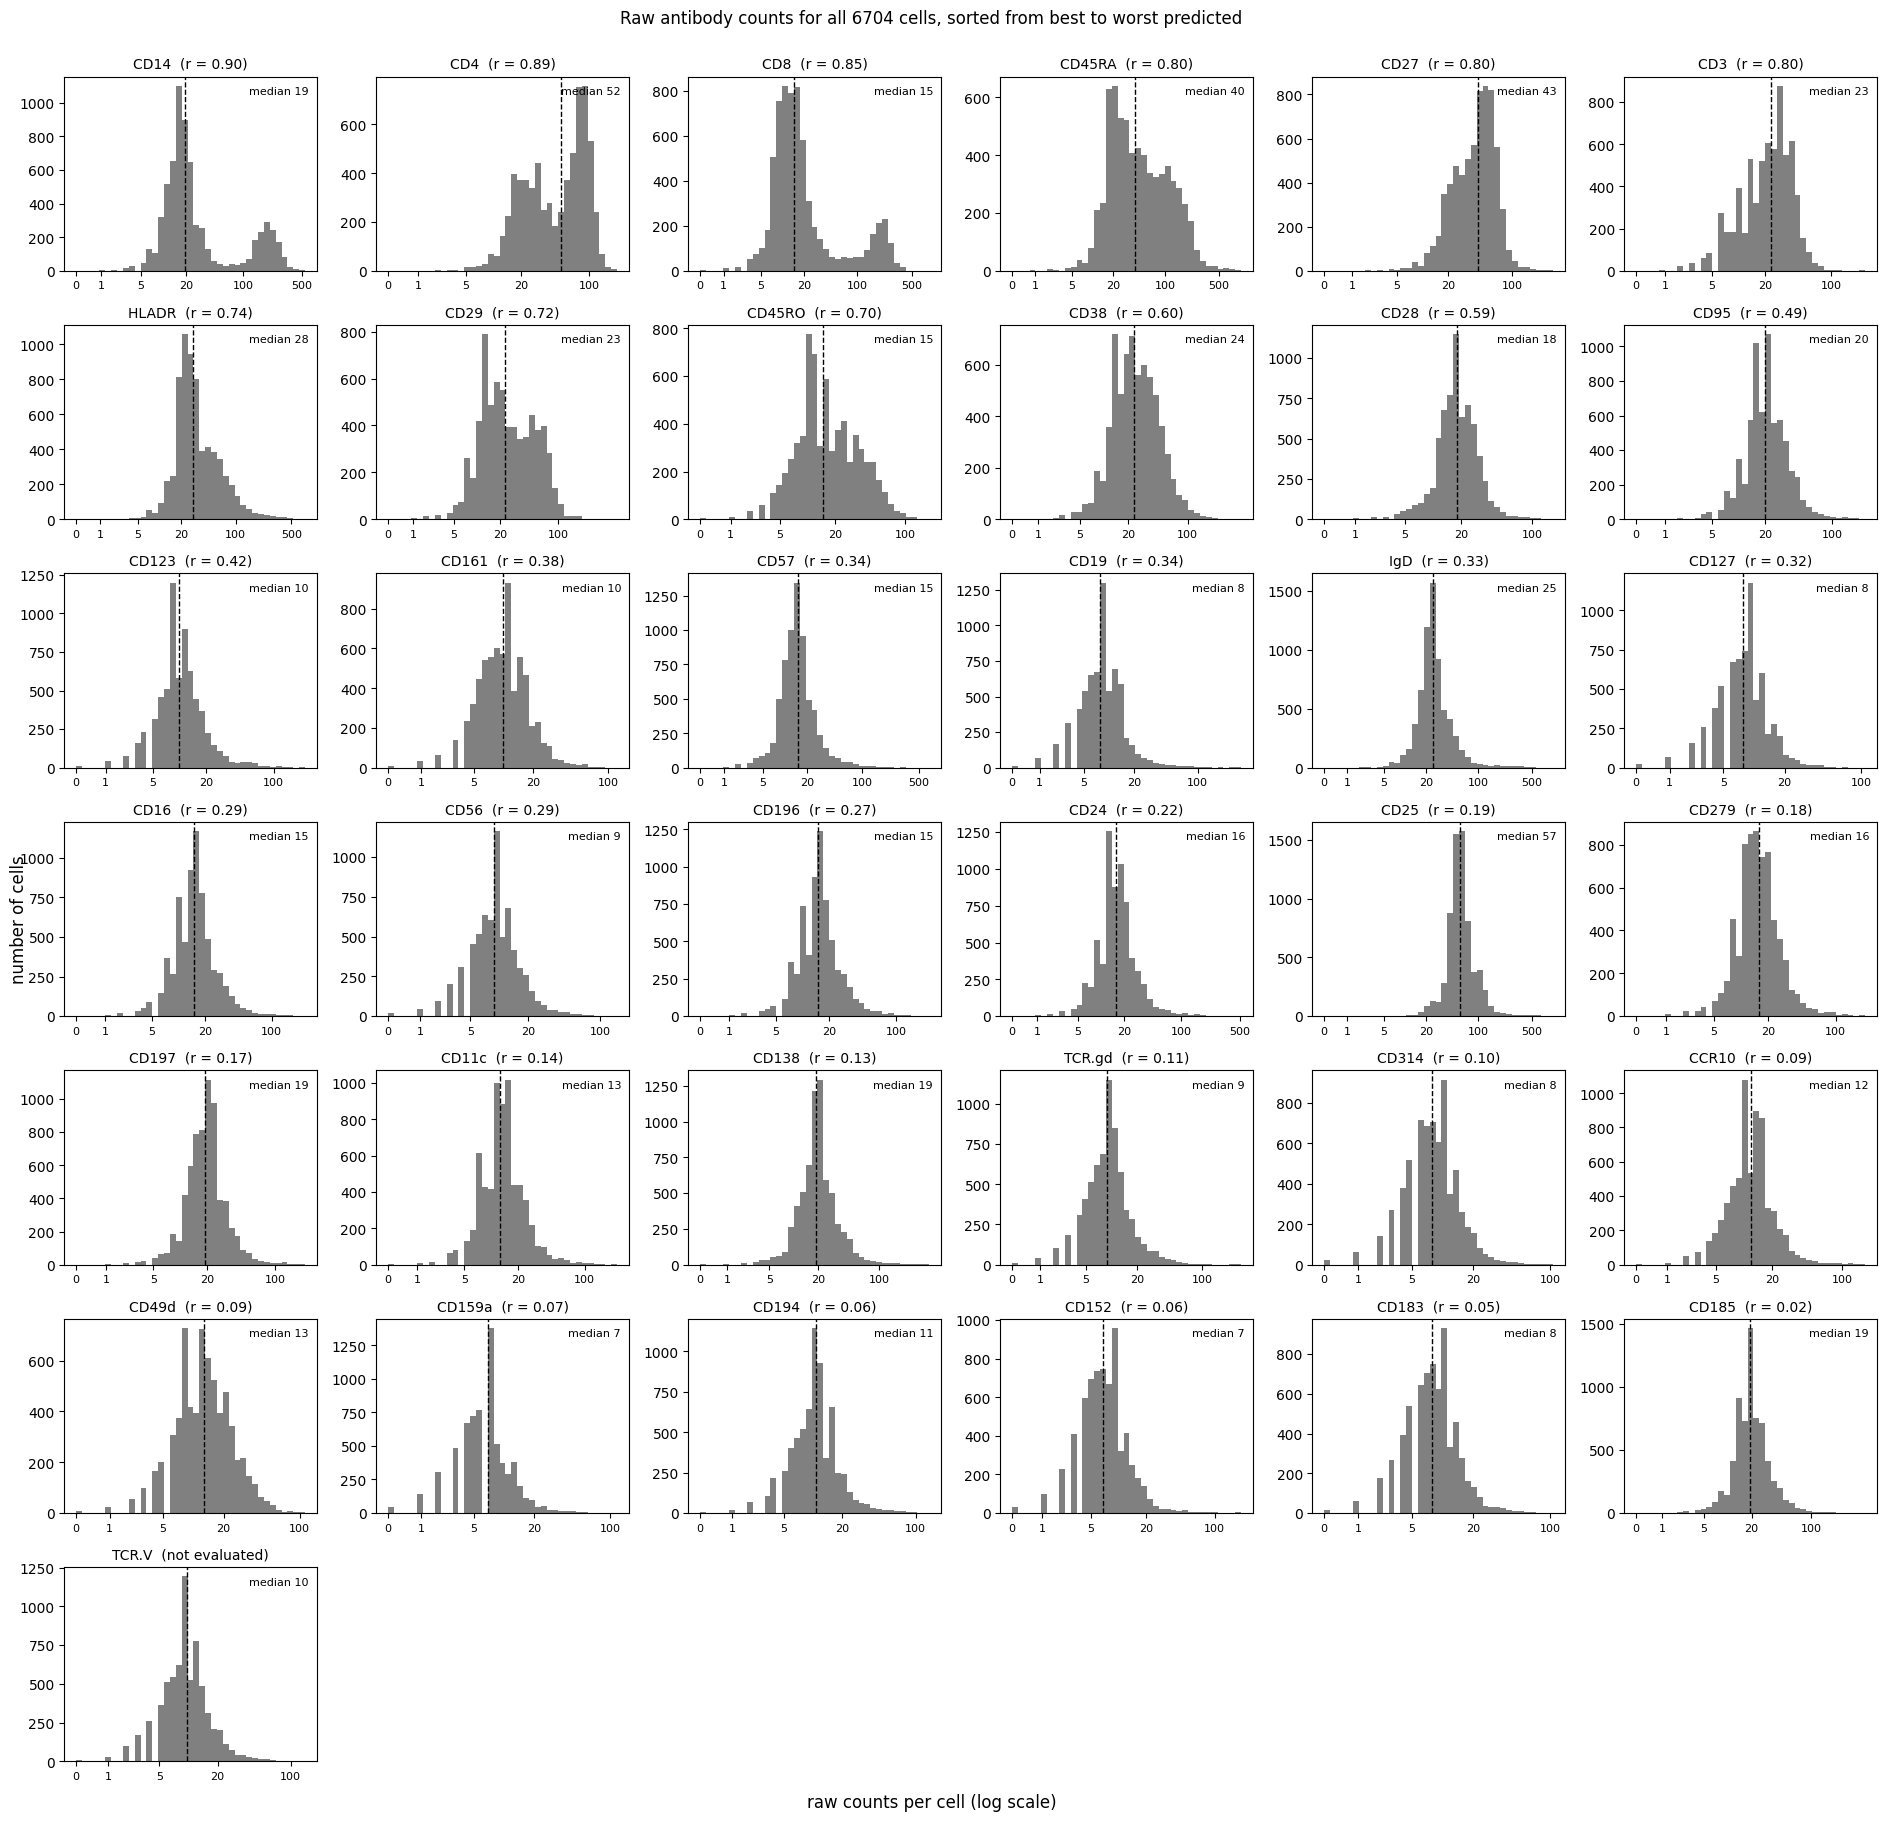

In [20]:
NCOLS = 6        # panels per row
LOG_Y = False    # set True to make small populations visible

r_of = results.set_index('protein')['pearson_r']
TOKEN_OF = {'CD49d': 'CD49'}                         # antibody name in the ADT file -> CAPTAIN token, where they differ
names = [v.strip() for v in adt_raw.var_names]
tokens = [TOKEN_OF.get(n, n) for n in names]
order = sorted(range(len(names)), key=lambda i: -r_of.get(tokens[i], -np.inf))   # best first, unevaluated last

X = adt_raw.X
X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)    # all cells in the ADT file, no filtering

nrows = int(np.ceil(len(order) / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(3.2 * NCOLS, 2.6 * nrows), squeeze=False)
for ax, i in zip(axes.flat, order):
    counts = X[:, i]
    bins = np.linspace(0, np.log1p(counts.max()), 40)
    ax.hist(np.log1p(counts), bins=bins, color='grey')
    ax.axvline(np.log1p(np.median(counts)), color='k', ls='--', lw=1)
    ticks = [t for t in [0, 1, 5, 20, 100, 500, 2000, 10000] if np.log1p(t) <= bins[-1]]
    ax.set_xticks(np.log1p(ticks)); ax.set_xticklabels(ticks, fontsize=8)
    r = r_of.get(tokens[i])
    ax.set_title(f'{names[i]}  (r = {r:.2f})' if r is not None else f'{names[i]}  (not evaluated)', fontsize=10)
    ax.text(0.97, 0.95, f'median {np.median(counts):.0f}', transform=ax.transAxes,
            ha='right', va='top', fontsize=8)
    if LOG_Y:
        ax.set_yscale('log')
for ax in list(axes.flat)[len(order):]:
    ax.axis('off')
fig.supxlabel('raw counts per cell (log scale)')
fig.supylabel('number of cells')
fig.suptitle(f'Raw antibody counts for all {X.shape[0]} cells, sorted from best to worst predicted', y=1.0)
plt.tight_layout()
plt.show()

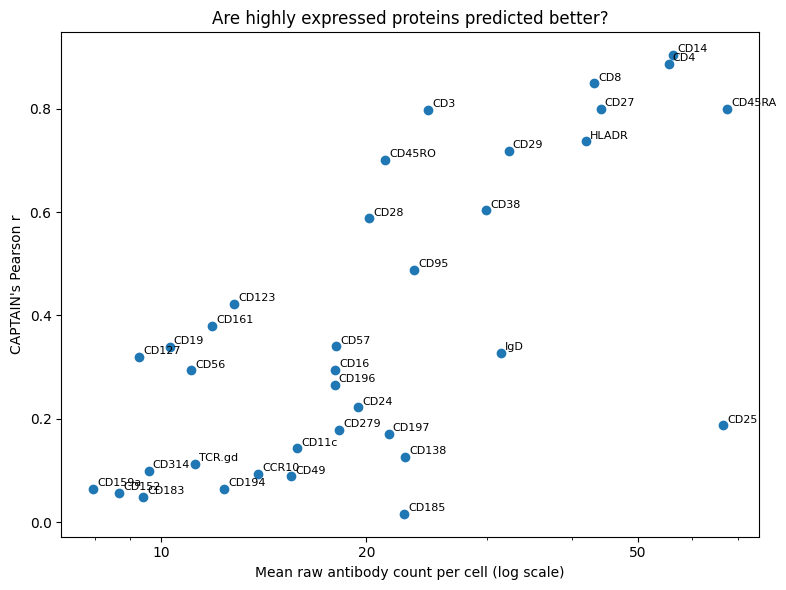

In [24]:
import os, pickle
from scipy.stats import spearmanr
import matplotlib.ticker as mticker

ALIGN_FILE = os.path.join(os.path.dirname(os.path.abspath(TOKEN_DICT)), 'csp_align_dict.pickle')

# raw counts for the same cells CAPTAIN predicted, matched to CAPTAIN's protein names
adt_cells = adt_raw[obs.index]
X = adt_cells.X
X = X.toarray() if hasattr(X, 'toarray') else np.asarray(X)
with open(ALIGN_FILE, 'rb') as f:
    csp_align_dict = pickle.load(f)
col_of = {}
for j, v in enumerate(adt_cells.var_names):
    col_of.setdefault(csp_align_dict.get(v, v).strip(), j)
    col_of.setdefault(v.strip(), j)

d = pd.DataFrame({'pearson_r': results.set_index('protein')['pearson_r']})
d['mean_count'] = [X[:, col_of[p]].mean() if p in col_of else np.nan for p in d.index]
d = d.dropna()
rho, pval = spearmanr(d['mean_count'], d['pearson_r'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(d['mean_count'], d['pearson_r'])
for p, row in d.iterrows():
    ax.annotate(p, (row['mean_count'], row['pearson_r']), fontsize=8, xytext=(3, 2), textcoords='offset points')
ax.set_xscale('log')
#ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.xaxis.set_major_locator(mticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))   # ticks at 1, 2, 5, 10, 20, 50, 100...
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel('Mean raw antibody count per cell (log scale)')
ax.set_ylabel("CAPTAIN's Pearson r")
ax.set_title(f'Are highly expressed proteins predicted better?')
plt.tight_layout()
plt.show()

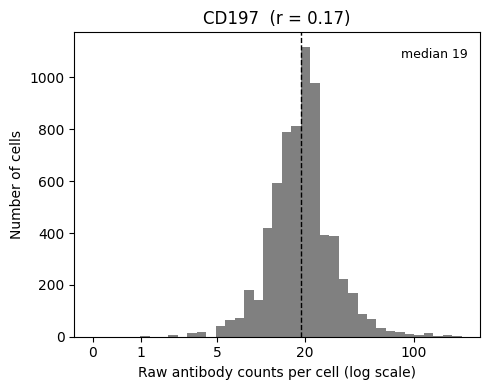

In [26]:
import os, pickle

PROTEIN = 'CD197'

ALIGN_FILE = os.path.join(os.path.dirname(os.path.abspath(TOKEN_DICT)), 'csp_align_dict.pickle')
with open(ALIGN_FILE, 'rb') as f:
    csp_align_dict = pickle.load(f)

# find the antibody for this protein (handles names like CD3-1 -> CD3)
col = next(j for j, v in enumerate(adt_raw.var_names)
           if csp_align_dict.get(v, v).strip() == PROTEIN or v.strip() == PROTEIN)
x = adt_raw[:, col].X
counts = np.asarray(x.todense() if hasattr(x, 'todense') else x).ravel()
r = results.set_index('protein')['pearson_r'].get(PROTEIN)

fig, ax = plt.subplots(figsize=(5, 4))
bins = np.linspace(0, np.log1p(counts.max()), 40)
ax.hist(np.log1p(counts), bins=bins, color='grey')
ax.axvline(np.log1p(np.median(counts)), color='k', ls='--', lw=1)
ax.text(0.97, 0.95, f'median {np.median(counts):.0f}', transform=ax.transAxes, ha='right', va='top', fontsize=9)

ticks = [t for t in [0, 1, 5, 20, 100, 500, 2000, 10000] if np.log1p(t) <= bins[-1]]
ax.set_xticks(np.log1p(ticks))
ax.set_xticklabels(ticks)
ax.set_xlabel('Raw antibody counts per cell (log scale)')
ax.set_ylabel('Number of cells')
ax.set_title(f'{PROTEIN}  (r = {r:.2f})' if r is not None else PROTEIN)
plt.tight_layout()
plt.show()